# 02 · Stable isotopes (Figure 10)

Code for: El Farchouni, A., et al. *Groundwater Recharge Mechanisms in the Haouz-Mejjate Aquifer (Morocco): Insights from Environmental Tracers and Self-Organizing Maps.* Groundwater for Sustainable Development (under review).

**What this notebook does**

Figure 10 of the article, two panels:
- **(a)** δ²H vs δ¹⁸O of the 342 samples against the GMWL (Craig, 1961), the Moroccan MWL (Ait Brahim et al., 2016) and the local MWL (Raibi et al., 2006), with the **local evaporation line (LEL)** fitted by ordinary least squares through the evaporation-affected samples (d-excess < 8 ‰ and δ¹⁸O > −8 ‰) and its intersection with the LMWL (un-evaporated source water).
- **(b)** δ¹⁸O vs sampling altitude of groundwater, springs and surface waters, with the local altitude line (LAL, Raibi et al., 2006) used to estimate the recharge elevation range.

| | |
|---|---|
| **Input** | `outputs/intermediate/data_EMMA1.xlsx` (from `01_isotope_dataset.ipynb`) |
| **Figure** | `outputs/figures/Figure10_d2H_d18O_and_Altitude_panel_LEL` |
| **Tables** | `outputs/tables/lel_results.txt`, `outputs/intermediate/isotopes_evap_classified.xlsx` |
| **Next notebook** | `05_EMMA/01_EMMA.ipynb` |

### <font color='orange'> **1) Packages, settings and paths** </font>

In [1]:
# ── Core ──────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

# ── Display settings ─────────────────────────────────────────────────
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 60)
pd.set_option('display.width', 120)

# ── Plot defaults ────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 800,
    'font.size': 12,
    'axes.labelsize': 15,
    'axes.titlesize': 14,
    'figure.figsize': (10, 6),
    'savefig.bbox': 'tight',
    'savefig.transparent': False,
})

# ── Paths (built from the repository root, so they work on any computer) ──
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data").is_dir() and (p / "notebooks").is_dir())
DATA_FILE    = ROOT / "data" / "All_data1.xlsx"
DIR_INTERMED = ROOT / "outputs" / "intermediate"
DIR_TABLES   = ROOT / "outputs" / "tables"
DIR_FIGURES  = ROOT / "outputs" / "figures"
for d in (DIR_INTERMED, DIR_TABLES, DIR_FIGURES):
    d.mkdir(parents=True, exist_ok=True)

C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


### <font color='orange'> **2) Load the isotope dataset** </font>

> Groundwater samples are labelled "Groundwater (Wells)" in the figure, because springs are also groundwater.

In [2]:
DATA_FILE = DIR_INTERMED / "data_EMMA1.xlsx"
print(f"  Input: {DATA_FILE.relative_to(ROOT)}  (exists: {DATA_FILE.is_file()})")

# ── Load data ─────────────────────────────────
df = pd.read_excel(DATA_FILE)
# Label used in the article figures (springs are also groundwater)
df["Type"] = df["Type"].replace({"Groundwater": "Groundwater (Wells)"})

print(f"\n  Loaded: {df.shape[0]} samples × {df.shape[1]} columns")
print(f"\n{df.head()}")

  Input: outputs\intermediate\data_EMMA1.xlsx  (exists: True)

  Loaded: 345 samples × 10 columns

                     Reference SampleID         X         Y        Z        Sampling date  Type  δ18O (‰ VSMOW)  \
0  (EL FARCHOUNI et al., 2025)       S1  264704.0  468828.0  2809.70  2025-01-10 00:00:00  Snow           -9.91   
1  (EL FARCHOUNI et al., 2025)       S2  264894.0  469092.0  2728.25  2025-01-10 00:00:00  Snow          -11.44   
2  (EL FARCHOUNI et al., 2025)       S3  264933.0  469332.0  2703.40  2025-01-10 00:00:00  Snow          -10.13   
3  (EL FARCHOUNI et al., 2025)       S4  266042.0  468235.0  2718.90  2025-01-10 00:00:00  Snow          -10.56   
4  (EL FARCHOUNI et al., 2025)       S5  266236.0  469982.0  2646.00  2025-01-10 00:00:00   Lac           -7.84   

   δ2H (‰ VSMOW)  d-excess (‰)  
0          -63.4         15.88  
1          -72.8         18.72  
2          -63.0         18.04  
3          -64.9         19.58  
4          -51.5         11.22  


In [3]:
# ── Filter: samples with both δ18O and δ2H ──────────────────────────────────
mask_iso = df["δ18O (‰ VSMOW)"].notna() & df["δ2H (‰ VSMOW)"].notna()
df_iso = df[mask_iso].copy()
print(f"Samples with both δ18O and δ2H: {len(df_iso)} / {len(df)}")

# ── Meteoric Water Lines ─────────────────────────────────────────────
GMWL = lambda x: 8.0  * x + 10.0    # Craig (1961)
MMWL = lambda x: 7.73 * x + 9.18    # Ait Brahim et al. (2016), Morocco-scale
LMWL = lambda x: 8.0  * x + 13.5    # Raibi et al. (2006), Tensift basin

# ── Marker / colour style per water Type ───────────────────────────────
TYPE_STYLE = {
    "Groundwater (Wells)": {"marker": "o", "color": "#1f77b4", "size": 40},
    "Spring":          {"marker": "^", "color": "#2ca02c", "size": 50},
    "Stream":          {"marker": "*", "color": "#d62728", "size": 60},
    "Snow":            {"marker": "D", "color": "#9467bd", "size": 40},
    "Rain":            {"marker": "v", "color": "#8c564b", "size": 45},
    "Dam":             {"marker": "X", "color": "#e377c2", "size": 50},
    "Lac":             {"marker": "P", "color": "#17becf", "size": 50},
    "Irrigation":      {"marker": "s", "color": "#bcbd22", "size": 40},
    "Canal (Zaraba)":  {"marker": "h", "color": "#ff7f0e", "size": 50},
}

print(f"MWL definitions loaded. TYPE_STYLE covers {len(TYPE_STYLE)} water types.")

Samples with both δ18O and δ2H: 342 / 345
MWL definitions loaded. TYPE_STYLE covers 9 water types.


### <font color='orange'> **3) Figure 10: δ²H vs δ¹⁸O with the LEL (a), and δ¹⁸O vs altitude with the LAL (b)** </font>

> Evaporation-affected samples: d-excess < 8 ‰ and δ¹⁸O > −8 ‰ (the δ¹⁸O cut-off excludes depleted sublimated snow and three aberrant values). The LEL is the OLS regression of δ²H on δ¹⁸O through these samples; a slope below 8 reflects kinetic fractionation (Craig and Gordon, 1965; Gat, 1996). Panel (a) is zoomed on the main cluster of points; panel (b) excludes snow and rain, which are inputs rather than recharged water.

Local Evaporation Line (LEL), Figure 10a
Classification: d-excess < 8.0 permil AND d18O > -8.0 permil
Evaporated samples (n)   : 57
Non-evaporated samples(n): 285
LEL slope                : 6.40  ± 0.55 (SE)
LEL intercept            : -7.43  ± 3.24 (SE)
R-squared                : 0.713
p-value                  : 1.49e-16
LEL equation             : d2H = 6.40 * d18O − 7.43
Un-evaporated source (LEL n LMWL): d18O = -13.05 permil, d2H = -90.9 permil
Interpretation: slope < 8 confirms kinetic fractionation by evaporation.

✓ Saved: outputs/tables/lel_results.txt + outputs/intermediate/isotopes_evap_classified.xlsx


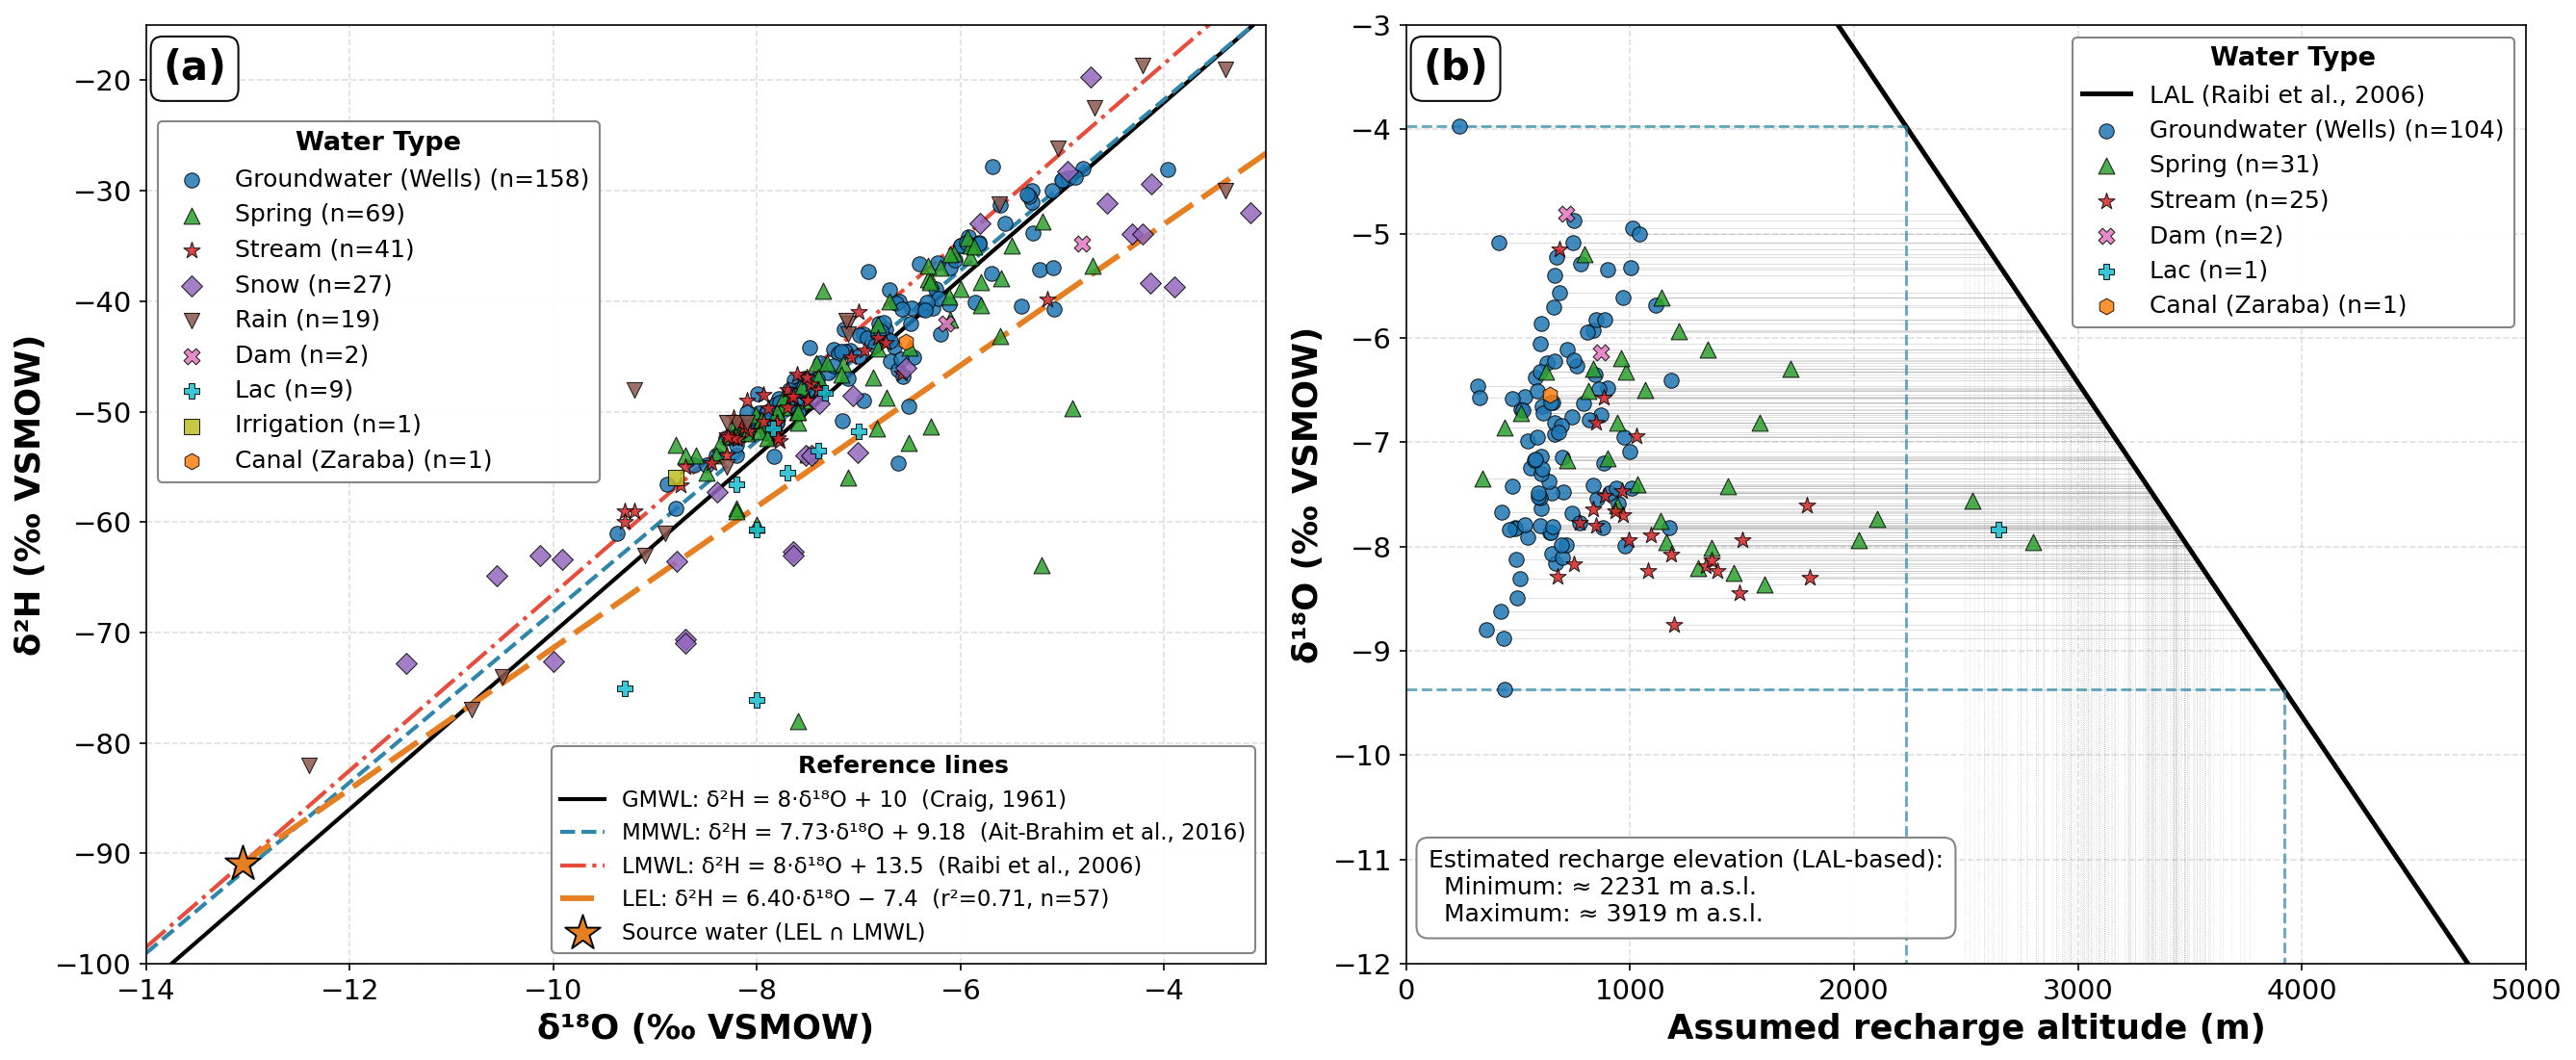

✓ Saved: Figure10_d2H_d18O_and_Altitude_panel_LEL.png
✓ Matches the article: LEL δ²H = 6.40 δ¹⁸O − 7.4 (r² = 0.71, n = 57); recharge altitude 2,231 to 3,919 m a.s.l.


In [4]:

# ── Classification thresholds for evaporation-affected samples ───────
DEXCESS_MAX = 8.0    # ‰, samples below this d-excess are evaporation-affected
D18O_MIN    = -8.0   # ‰, keep only enriched samples (liquid-water evaporation)

# Font sizes
LABEL_FS = 17; TICK_FS = 14; LEG_FS = 12
LEG_TITLE_FS = 13; ANNO_FS = 12; PANEL_LBL_FS = 20

# panel-label style: inside top-left corner, white box, always visible
PANEL_BBOX = dict(boxstyle='round,pad=0.3', fc='white', ec='black', lw=1.0, alpha=0.95)

# LAL equation (Raibi et al., 2006)
LAL_slope, LAL_intercept = -0.0032, 3.17
LAL     = lambda alt: LAL_slope * alt + LAL_intercept
LAL_inv = lambda d18O: (d18O - LAL_intercept) / LAL_slope

# ── Classify samples & fit the Local Evaporation Line (LEL) ──────────
df_iso["d_excess_calc"] = df_iso["δ2H (‰ VSMOW)"] - 8 * df_iso["δ18O (‰ VSMOW)"]
df_iso["evap_group"] = np.where(
    (df_iso["d_excess_calc"] < DEXCESS_MAX) & (df_iso["δ18O (‰ VSMOW)"] > D18O_MIN),
    "evaporated", "non_evaporated")
df_evap = df_iso[df_iso["evap_group"] == "evaporated"].copy()

if len(df_evap) < 5:
    print(f"⚠ WARNING: only {len(df_evap)} evaporated samples, LEL fit poorly constrained.")

# OLS regression (slope, intercept, r, p-value, SE)
lr = stats.linregress(df_evap["δ18O (‰ VSMOW)"], df_evap["δ2H (‰ VSMOW)"])
S_lel, b_lel, r2_lel = lr.slope, lr.intercept, lr.rvalue ** 2

# intersection LEL ∩ LMWL (δ²H = 8·δ¹⁸O + 13.5) → un-evaporated source water
x_src = (b_lel - 13.5) / (8.0 - S_lel)
y_src = 8.0 * x_src + 13.5
sign  = "+" if b_lel >= 0 else "−"
lel_label = (f"LEL: δ²H = {S_lel:.2f}·δ¹⁸O {sign} {abs(b_lel):.1f}  "
             f"(r²={r2_lel:.2f}, n={len(df_evap)})")

# ── Report + write lel_results.txt ───────────────────────────────────
lel_report = (
    "Local Evaporation Line (LEL), Figure 10a\n"
    "=============================================\n"
    f"Classification: d-excess < {DEXCESS_MAX} permil AND d18O > {D18O_MIN} permil\n"
    f"Evaporated samples (n)   : {len(df_evap)}\n"
    f"Non-evaporated samples(n): {(df_iso['evap_group']=='non_evaporated').sum()}\n"
    f"LEL slope                : {S_lel:.2f}  ± {lr.stderr:.2f} (SE)\n"
    f"LEL intercept            : {b_lel:.2f}  ± {lr.intercept_stderr:.2f} (SE)\n"
    f"R-squared                : {r2_lel:.3f}\n"
    f"p-value                  : {lr.pvalue:.2e}\n"
    f"LEL equation             : d2H = {S_lel:.2f} * d18O {sign} {abs(b_lel):.2f}\n"
    f"Un-evaporated source (LEL n LMWL): d18O = {x_src:.2f} permil, d2H = {y_src:.1f} permil\n"
    "Interpretation: slope < 8 confirms kinetic fractionation by evaporation.\n"
)
print(lel_report)
with open(DIR_TABLES / "lel_results.txt", "w", encoding="utf-8") as fh:
    fh.write(lel_report)
# classified data for audit
df_iso[["SampleID", "Reference", "Type", "δ18O (‰ VSMOW)", "δ2H (‰ VSMOW)",
        "d_excess_calc", "evap_group"]].to_excel(
    DIR_INTERMED / "isotopes_evap_classified.xlsx", index=False)
print("✓ Saved: outputs/tables/lel_results.txt + outputs/intermediate/isotopes_evap_classified.xlsx")

# ══════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
ax1, ax2 = axes

# ══════ Panel (a): δ²H vs δ¹⁸O  +  LEL ═══════════════════════════════
X_MIN, X_MAX = -14, -3
Y_MIN, Y_MAX = -100, -15
df_plot = df_iso[(df_iso["δ18O (‰ VSMOW)"] >= X_MIN) & (df_iso["δ18O (‰ VSMOW)"] <= X_MAX) &
                 (df_iso["δ2H (‰ VSMOW)"]  >= Y_MIN) & (df_iso["δ2H (‰ VSMOW)"]  <= Y_MAX)].copy()

x_line = np.linspace(X_MIN, X_MAX, 100)
ax1.plot(x_line, GMWL(x_line), 'k-',  lw=2.0, zorder=1,
         label="GMWL: δ²H = 8·δ¹⁸O + 10  (Craig, 1961)")
ax1.plot(x_line, MMWL(x_line), '--',  color="#2E86AB", lw=2.0, zorder=1,
         label="MMWL: δ²H = 7.73·δ¹⁸O + 9.18  (Ait-Brahim et al., 2016)")
ax1.plot(x_line, LMWL(x_line), '-.',  color="#E74C3C", lw=2.0, zorder=1,
         label="LMWL: δ²H = 8·δ¹⁸O + 13.5  (Raibi et al., 2006)")

# ── Local Evaporation Line (from source water to enriched end) ───────
x_lel = np.linspace(x_src, df_evap["δ18O (‰ VSMOW)"].max() + 0.3, 50)
ax1.plot(x_lel, S_lel * x_lel + b_lel, color="#E67E22", lw=2.8, ls=(0, (6, 2)),
         zorder=2, label=lel_label)
# source-water star - identified through the legend (no overlapping text label)
ax1.scatter([x_src], [y_src], marker="*", s=340, c="#E67E22",
            edgecolors="black", linewidths=0.9, zorder=8,
            label="Source water (LEL ∩ LMWL)")

# Scatter by Type
for wtype, style in TYPE_STYLE.items():
    subset = df_plot[df_plot["Type"] == wtype]
    if len(subset) == 0:
        continue
    ax1.scatter(subset["δ18O (‰ VSMOW)"], subset["δ2H (‰ VSMOW)"],
                marker=style["marker"], c=style["color"], s=style["size"] + 15,
                edgecolors="black", linewidths=0.5, alpha=0.85,
                label=f"{wtype} (n={len(subset)})", zorder=3)

ax1.set_xlim(X_MIN, X_MAX)
ax1.set_ylim(Y_MIN, Y_MAX)
ax1.set_xlabel("δ¹⁸O (‰ VSMOW)", fontsize=LABEL_FS, fontweight='bold')
ax1.set_ylabel("δ²H (‰ VSMOW)",  fontsize=LABEL_FS, fontweight='bold')
ax1.tick_params(axis='both', labelsize=TICK_FS)
ax1.grid(True, ls="--", alpha=0.25, color='gray')

h1, l1 = ax1.get_legend_handles_labels()
# first 5 handles = GMWL, MMWL, LMWL, LEL, Source-water star
leg1a = ax1.legend(h1[:5], l1[:5], loc="lower right", fontsize=LEG_FS - 1,
                   framealpha=0.95, edgecolor="gray",
                   title="Reference lines", title_fontsize=LEG_TITLE_FS - 1)
leg1a.get_title().set_fontweight('bold')
ax1.add_artist(leg1a)
# Water Type legend pushed slightly down so it clears the (a) panel label
leg1b = ax1.legend(h1[5:], l1[5:], loc="upper left", bbox_to_anchor=(0.0, 0.91),
                   fontsize=LEG_FS, framealpha=0.95, edgecolor="gray",
                   title="Water Type", title_fontsize=LEG_TITLE_FS, ncol=1)
leg1b.get_title().set_fontweight('bold')

# Panel label INSIDE the axes (top-left, white box) - always visible
ax1.text(0.015, 0.975, '(a)', transform=ax1.transAxes,
         fontsize=PANEL_LBL_FS, fontweight='bold', va='top', ha='left',
         bbox=PANEL_BBOX, zorder=20)

# ══════ Panel (b): δ¹⁸O vs Altitude (LAL) - Snow & Rain excluded ═════
EXCLUDE_B = ["Snow", "Rain"]
mask_alt = df["δ18O (‰ VSMOW)"].notna() & df["Z"].notna() & ~df["Type"].isin(EXCLUDE_B)
df_alt = df[mask_alt].copy()
df_alt["Recharge_Alt"] = LAL_inv(df_alt["δ18O (‰ VSMOW)"])

gw_sp = df_alt[df_alt["Type"].isin(["Groundwater (Wells)", "Spring"])]
d18O_min_gw, d18O_max_gw = gw_sp["δ18O (‰ VSMOW)"].min(), gw_sp["δ18O (‰ VSMOW)"].max()
alt_high, alt_low = LAL_inv(d18O_min_gw), LAL_inv(d18O_max_gw)

alt_line = np.linspace(0, 5000, 200)
ax2.plot(alt_line, LAL(alt_line), 'k-', lw=2.4, zorder=2,
         label="LAL (Raibi et al., 2006)")

for _, row in df_alt.iterrows():
    d18O_val, z_sample, recharge_alt = row["δ18O (‰ VSMOW)"], row["Z"], row["Recharge_Alt"]
    ax2.plot([z_sample, recharge_alt], [d18O_val, d18O_val],
             color='gray', lw=0.4, alpha=0.3, zorder=0)
    ax2.plot([recharge_alt, recharge_alt], [d18O_val, -12],
             color='gray', lw=0.4, alpha=0.3, zorder=0, ls=':')

for wtype, style in TYPE_STYLE.items():
    if wtype in EXCLUDE_B:
        continue
    subset = df_alt[df_alt["Type"] == wtype]
    if len(subset) == 0:
        continue
    ax2.scatter(subset["Z"], subset["δ18O (‰ VSMOW)"],
                marker=style["marker"], c=style["color"], s=style["size"] + 15,
                edgecolors="black", linewidths=0.5, alpha=0.85,
                label=f"{wtype} (n={len(subset)})", zorder=4)

ax2.plot([0, alt_high], [d18O_min_gw, d18O_min_gw], ls='--', color='#2E86AB', lw=1.4, alpha=0.7)
ax2.plot([alt_high, alt_high], [d18O_min_gw, -12],  ls='--', color='#2E86AB', lw=1.4, alpha=0.7)
ax2.plot([0, alt_low],  [d18O_max_gw, d18O_max_gw], ls='--', color='#2E86AB', lw=1.4, alpha=0.7)
ax2.plot([alt_low, alt_low],   [d18O_max_gw, -12],  ls='--', color='#2E86AB', lw=1.4, alpha=0.7)

textstr = (f"Estimated recharge elevation (LAL-based):\n"
           f"  Minimum: ≈ {alt_low:.0f} m a.s.l.\n"
           f"  Maximum: ≈ {alt_high:.0f} m a.s.l.")
props = dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.95)
ax2.text(0.02, 0.04, textstr, transform=ax2.transAxes, fontsize=ANNO_FS,
         verticalalignment='bottom', horizontalalignment='left', bbox=props)

ax2.set_xlim(0, 5000)
ax2.set_ylim(-12, -3)
ax2.set_xlabel("Assumed recharge altitude (m)", fontsize=LABEL_FS, fontweight='bold')
ax2.set_ylabel("δ¹⁸O (‰ VSMOW)",          fontsize=LABEL_FS, fontweight='bold')
ax2.tick_params(axis='both', labelsize=TICK_FS)
ax2.grid(True, ls="--", alpha=0.25, color='gray')

h2, l2 = ax2.get_legend_handles_labels()
leg2 = ax2.legend(h2, l2, loc="upper right", fontsize=LEG_FS,
                  framealpha=0.95, edgecolor="gray",
                  title="Water Type", title_fontsize=LEG_TITLE_FS, ncol=1)
leg2.get_title().set_fontweight('bold')

# Panel label INSIDE the axes (top-left, white box) - always visible
ax2.text(0.015, 0.975, '(b)', transform=ax2.transAxes,
         fontsize=PANEL_LBL_FS, fontweight='bold', va='top', ha='left',
         bbox=PANEL_BBOX, zorder=20)

plt.tight_layout()
fig.savefig(DIR_FIGURES / "Figure10_d2H_d18O_and_Altitude_panel_LEL.png", dpi=800)
plt.show()
print("✓ Saved: Figure10_d2H_d18O_and_Altitude_panel_LEL.png")

# ── Check against the article ────────────────────────────────────────
assert len(df_iso) == 342 and len(df_evap) == 57
assert (round(S_lel, 2), round(b_lel, 1), round(r2_lel, 2)) == (6.40, -7.4, 0.71)   # LEL in the Figure 10 caption
assert (round(alt_low), round(alt_high)) == (2231, 3919)                              # recharge altitudes in the article
print("✓ Matches the article: LEL δ²H = 6.40 δ¹⁸O − 7.4 (r² = 0.71, n = 57); recharge altitude 2,231 to 3,919 m a.s.l.")

---
**Figure:** Figure 10 in `outputs/figures/`; LEL parameters in `outputs/tables/lel_results.txt`

**Next:** `05_EMMA/01_EMMA.ipynb` (end-member mixing analysis; Figure 11, SM10-SM12)